# Optimal viewing geometries

The uncertainty of $R_{ss}$ due to unknown wind speed and aerosols depends on the observation
geometry. Harmel (2023) showed that it is lowest for geometries whose scattering angle $\Theta$
(between the Sun direction and the direction of the sky radiance reflected toward the sensor) is
about 120-140°, approximately 135° irrespective of the wavelength. Since the Sun moves during the
day, the relative azimuth $\Delta\phi$ of the sensor has to be adapted to the Sun zenith angle to keep
$\Theta$ constant, e.g. for a viewing zenith angle of 40°:

| $\theta_s$ | recommended $\Delta\phi$ ($\Theta \approx 135^\circ$) |
|---|---|
| 20° | 90° |
| 80° | 150° |

This tutorial computes $\Delta\phi$ for a given scattering angle and shows $R_{ss}$ along these
geometries.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from surface_sky_radiance_ratio import lut

## Relative azimuth for a given scattering angle

With the convention of the look-up tables ($\Delta\phi = 0$ when the Sun and the sensor are in
opposition), the scattering angle satisfies

$$
\cos\Theta = -\cos\theta_s \cos\theta_v - \sin\theta_s \sin\theta_v \cos\Delta\phi
$$

so that

$$
\Delta\phi = \arccos\left(\frac{\cos\Theta + \cos\theta_s\cos\theta_v}{\sin\theta_s\sin\theta_v}\right).
$$

There is no solution (NaN) when the Sun is too high for the requested $\Theta$.

In [2]:
def scat_to_azi(scat_ang, sza, vza=40):
    """
    Relative azimuth (deg.) giving the scattering angle scat_ang (deg.) for the solar and
    viewing zenith angles sza and vza (deg.); NaN when no azimuth gives scat_ang.
    """
    scat_angr, szar, vzar = np.radians(scat_ang), np.radians(sza), np.radians(vza)
    cos_azi = (np.cos(scat_angr) + np.cos(szar) * np.cos(vzar)) / (np.sin(szar) * np.sin(vzar))
    with np.errstate(invalid='ignore'):
        return np.degrees(np.arccos(cos_azi))


for sza in [20, 40, 60, 80]:
    print(f'sza = {sza:2d} deg.: azimuth = {scat_to_azi(135, sza):5.1f} deg. for a scattering angle of 135 deg.')

sza = 20 deg.: azimuth =  86.7 deg. for a scattering angle of 135 deg.
sza = 40 deg.: azimuth = 106.9 deg. for a scattering angle of 135 deg.
sza = 60 deg.: azimuth = 125.6 deg. for a scattering angle of 135 deg.
sza = 80 deg.: azimuth = 155.1 deg. for a scattering angle of 135 deg.


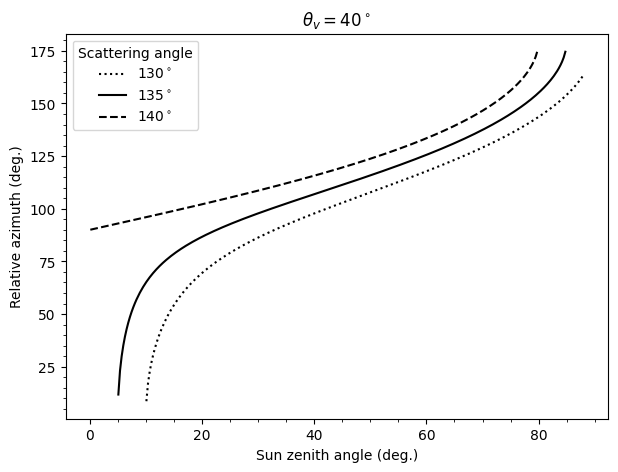

In [3]:
szas = np.linspace(0.1, 88, 300)
fig, ax = plt.subplots(figsize=(7, 5))
for scat, ls in zip([130, 135, 140], [':', '-', '--']):
    ax.plot(szas, scat_to_azi(scat, szas, vza=40), color='black', ls=ls, label=f'{scat}$^\\circ$')
ax.set_xlabel('Sun zenith angle (deg.)')
ax.set_ylabel('Relative azimuth (deg.)')
ax.minorticks_on()
ax.legend(title='Scattering angle')
ax.set_title(r'$\theta_v = 40^\circ$');

## $R_{ss}$ along the optimal geometries

Along the 135° scattering-angle path, $R_{ss}$ stays close to the flat-surface Fresnel reflectance and
depends little on the wind speed, whereas a fixed azimuth (here 90°) gives larger and more variable
values when the Sun gets low. The relative azimuths are limited to the range of the sliced table
(45-160°).

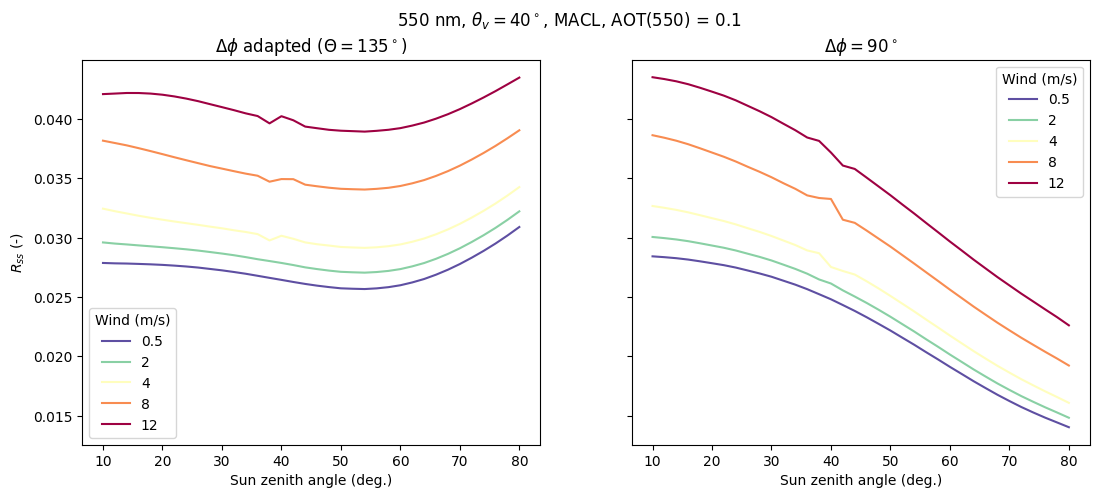

In [4]:
rss = lut()
ds = rss.load()

szas = np.arange(10, 81, 2.)
azis = np.clip(scat_to_azi(135, szas, vza=40), 45, 160)
winds = [0.5, 2, 4, 8, 12]
cmap = plt.cm.Spectral_r

fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
Rss = ds.Rss.sel(model='MACL_rh70').interp(vza=40, wl=550, aot_ref=0.1)
for i, wind in enumerate(winds):
    color = cmap(i / (len(winds) - 1))
    path = [float(Rss.interp(wind=wind, sza=s, azi=a)) for s, a in zip(szas, azis)]
    axs[0].plot(szas, path, color=color, label=f'{wind:g}')
    Rss.interp(wind=wind, azi=90, sza=szas).plot(ax=axs[1], color=color, label=f'{wind:g}')
axs[0].set_title(r'$\Delta\phi$ adapted ($\Theta = 135^\circ$)')
axs[1].set_title(r'$\Delta\phi = 90^\circ$')
for ax in axs:
    ax.set_xlabel('Sun zenith angle (deg.)')
    ax.legend(title='Wind (m/s)')
axs[0].set_ylabel(r'$R_{ss}$ (-)')
axs[1].set_ylabel('')
fig.suptitle(r'550 nm, $\theta_v = 40^\circ$, MACL, AOT(550) = 0.1');